In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from geopy.distance import geodesic

In [4]:
# Load dataset
df = pd.read_csv("/content/uber.csv")
df.head()
df.tail(8)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB


In [5]:
# Drop unnecessary columns
df.drop(['Unnamed: 0', 'key'], axis=1, inplace=True)

In [6]:
# Drop missing values
df = df.dropna()

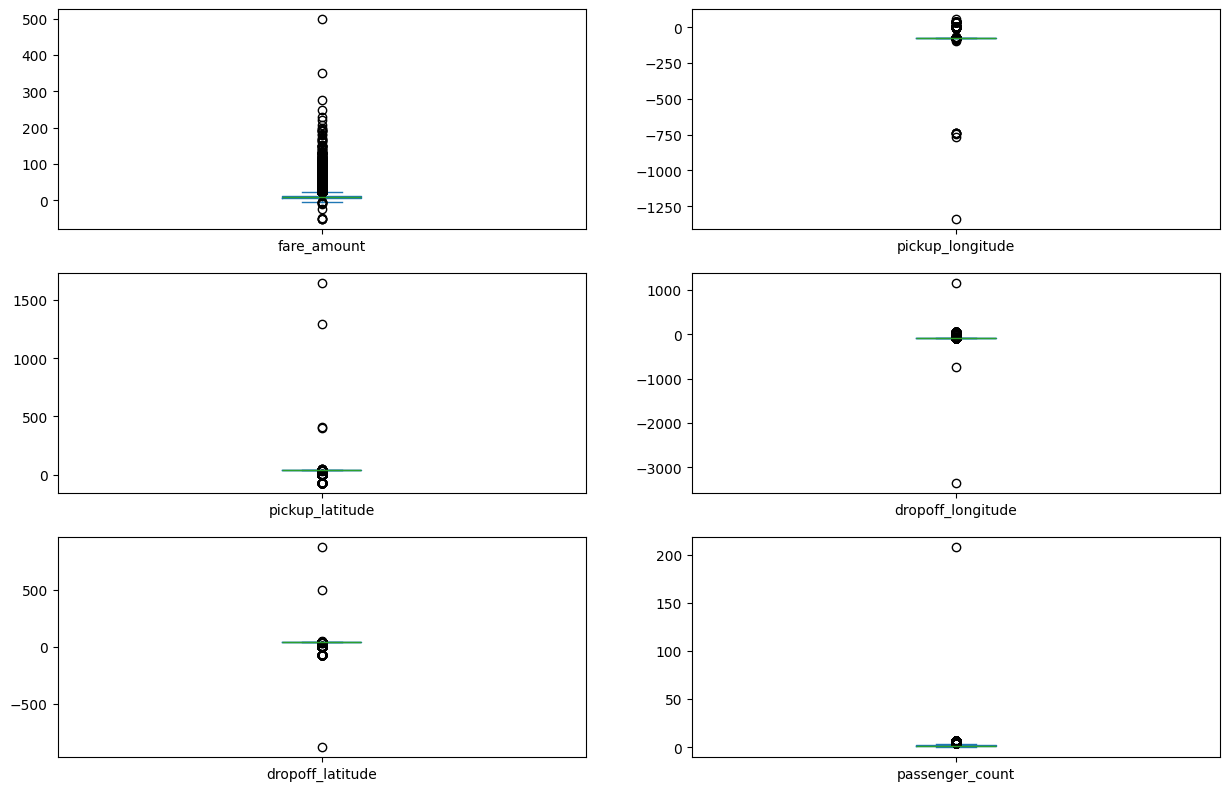

In [7]:
# Identify outliers
df.plot(kind="box", subplots=True, layout=(6, 2), figsize=(15, 20))
plt.show()

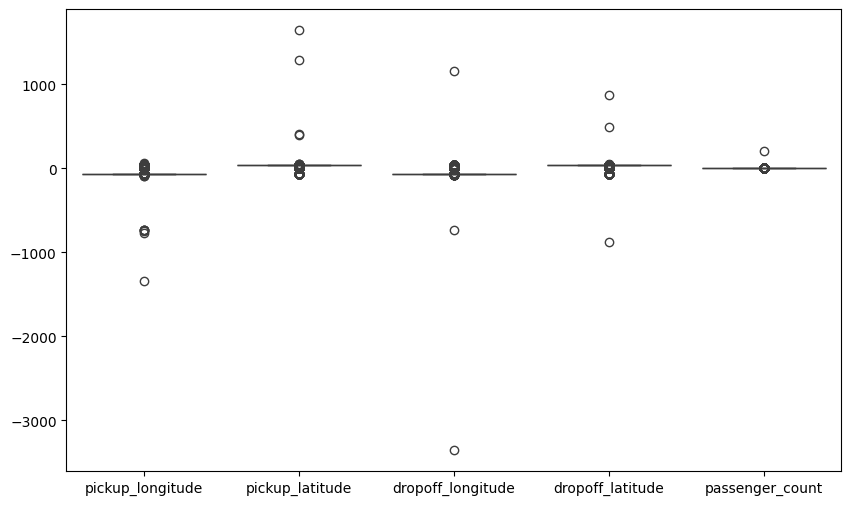

In [8]:
features = df[['pickup_longitude', 'pickup_latitude',
               'dropoff_longitude', 'dropoff_latitude',
               'passenger_count']]

plt.figure(figsize=(10, 6))
sns.boxplot(data=features)
plt.show()

In [9]:
# Remove outliers using IQR
def remove_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    return df[
        (df[column] >= lower_bound) &
        (df[column] <= upper_bound)
    ]

columns_to_check = [
    'fare_amount', 'pickup_longitude',
    'pickup_latitude', 'dropoff_longitude',
    'dropoff_latitude', 'passenger_count'
]

data_cleaned = df.copy()

for column in columns_to_check:
    data_cleaned = remove_outliers(data_cleaned, column)

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", data_cleaned.shape)

features1 = data_cleaned[
    ['pickup_longitude', 'pickup_latitude',
     'dropoff_longitude', 'dropoff_latitude',
     'passenger_count']
]

target = data_cleaned['fare_amount']

Original dataset shape: (199999, 7)
Cleaned dataset shape: (148074, 7)


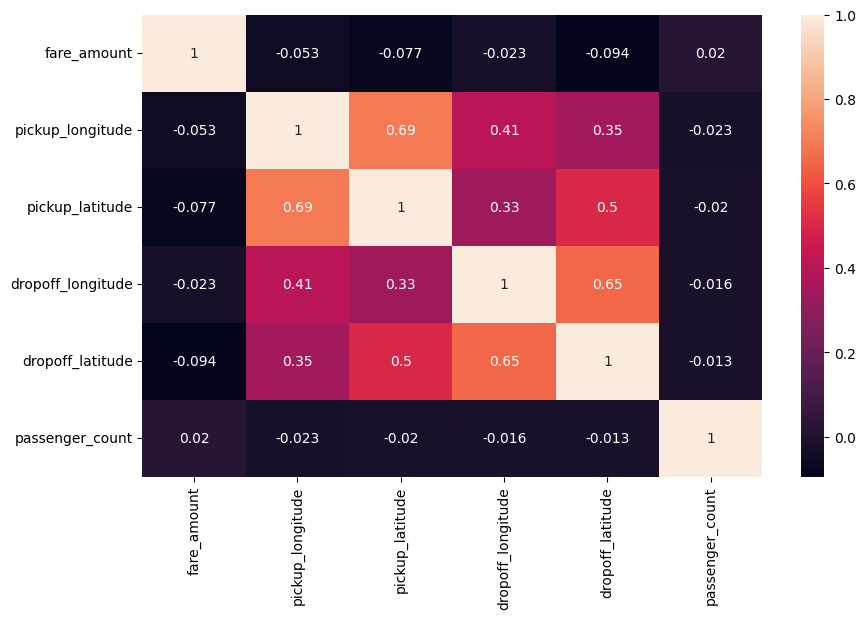

In [10]:
# Correlation matrix
data_numeric = data_cleaned.select_dtypes(include=[np.number])

correlation_matrix = data_numeric.corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True)
plt.show()

In [11]:
# Check missing values
df.isnull().sum()

,0
fare_amount,0
pickup_datetime,0
pickup_longitude,0
pickup_latitude,0
dropoff_longitude,0
dropoff_latitude,0
passenger_count,0


In [12]:
# Remove missing values and duplicates
df.dropna(inplace=True)
df.drop_duplicates(inplace=True)

In [13]:
# Filter valid coordinates
df = df[
    (df['pickup_latitude'].between(-90, 90)) &
    (df['dropoff_latitude'].between(-90, 90)) &
    (df['pickup_longitude'].between(-180, 180)) &
    (df['dropoff_longitude'].between(-180, 180))
].copy()

In [14]:
# Calculate distance
def calculate_distance(row):
    pickup = (
        row['pickup_latitude'],
        row['pickup_longitude']
    )

    dropoff = (
        row['dropoff_latitude'],
        row['dropoff_longitude']
    )

    return geodesic(pickup, dropoff).km

df['distance_km'] = df.apply(calculate_distance, axis=1)

In [15]:
# Remove invalid fares and outliers
df = df[
    (df['fare_amount'] > 0) &
    (df['fare_amount'] < 100)
]

df = df[df['distance_km'] < 100].copy()

In [16]:
# Extract useful features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['hour'] = df['pickup_datetime'].dt.hour
df['day'] = df['pickup_datetime'].dt.dayofweek
df['month'] = df['pickup_datetime'].dt.month

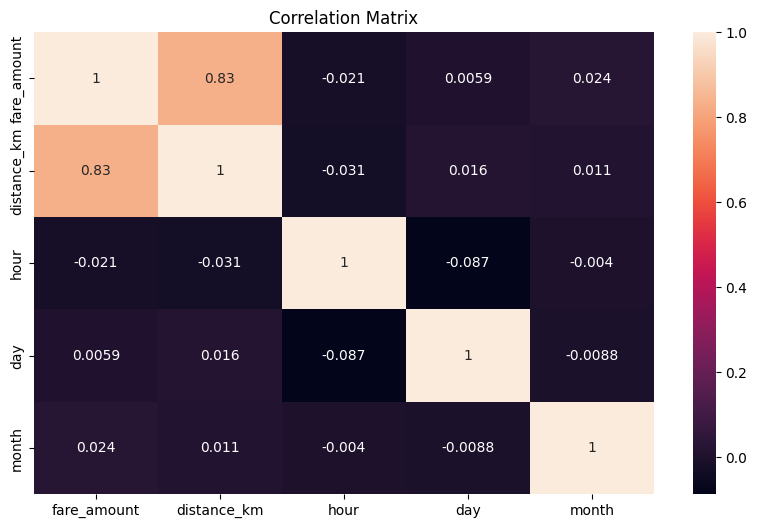

In [17]:
# Correlation matrix
plt.figure(figsize=(10, 6))

sns.heatmap(
    df[['fare_amount', 'distance_km',
        'hour', 'day', 'month']].corr(),
    annot=True
)

plt.title('Correlation Matrix')
plt.show()

In [18]:
# Prepare data
features = ['distance_km', 'hour', 'day', 'month']

X = df[features]
y = df['fare_amount']

In [19]:
# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [20]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

In [21]:
# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

In [22]:
# Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)

y_pred_ridge = ridge.predict(X_test)

In [23]:
# Lasso Regression
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)

y_pred_lasso = lasso.predict(X_test)

In [24]:
# Evaluate Models
def evaluate_model(y_test, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    print(
        f"{model_name}:\n"
        f"RMSE: {rmse:.2f}, "
        f"R2 Score: {r2:.4f}\n"
    )

evaluate_model(y_test, y_pred_lr, 'Linear Regression')
evaluate_model(y_test, y_pred_ridge, 'Ridge Regression')
evaluate_model(y_test, y_pred_lasso, 'Lasso Regression')

Linear Regression:
RMSE: 5.11, R2 Score: 0.7057

Ridge Regression:
RMSE: 5.11, R2 Score: 0.7057

Lasso Regression:
RMSE: 5.11, R2 Score: 0.7049



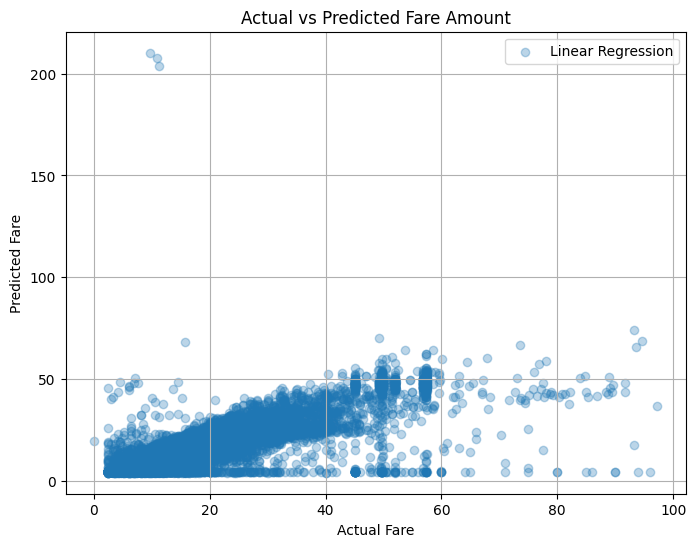

In [25]:
# Actual vs Predicted Fare
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test, y_pred_lr,
    alpha=0.3,
    label='Linear Regression'
)

plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Actual vs Predicted Fare Amount")
plt.legend()
plt.grid(True)
plt.show()